In [1]:
%load_ext autoreload
%autoreload 2

from scripts.utils import *
from scripts.visualisation import *

# Probes Performance

In [2]:
%load_ext autoreload
%autoreload 2

from scripts.visualisation.plot_classification import *

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Load the pre-computed performance scores

In [3]:
base_path = "./outputs/raw_outputs/ccgp/"
dataset_name = "twinviews"
models_names = ["Llama-3.1-8B","Llama-3.1-8B-Instruct","OLMo-2-1124-7B-Instruct"]

MODELS_COLORS = {
    "OLMo-2-1124-7B-Instruct":"hotpink",
    "Llama-3.1-8B":"cornflowerblue",
    "Llama-3.1-8B-Instruct":"royalblue",
    "TF-IDF":"grey",
}

include_tfidf = True

In [4]:
models_layers = {}
results_ccgp_label = {}

for model_name in models_names:
    file_ccgp_path = os.path.join(base_path, dataset_name, f"{model_name}.json")

    results_ccgp_label[model_name] = load_json_dict(file_ccgp_path)
    models_layers[model_name] = np.arange(len(results_ccgp_label[model_name]))

In [5]:
if include_tfidf:
    tfidf_file_ccgp_path = os.path.join(base_path, dataset_name, f"TFIDF.json")
    baselines_results_ccgp_label = {"TF-IDF": load_json_dict(tfidf_file_ccgp_path)}
else:
    baselines_results_ccgp_label = None

## Within Condition Performance (WCP)

In [6]:
wcp_models, wcp_tfidf  = prepare_classification_scores_for_plot(
    ccgp=False, # -> WCP
    results_ccgp=results_ccgp_label,
    results_static=baselines_results_ccgp_label,
    loading_static_args=None,
)

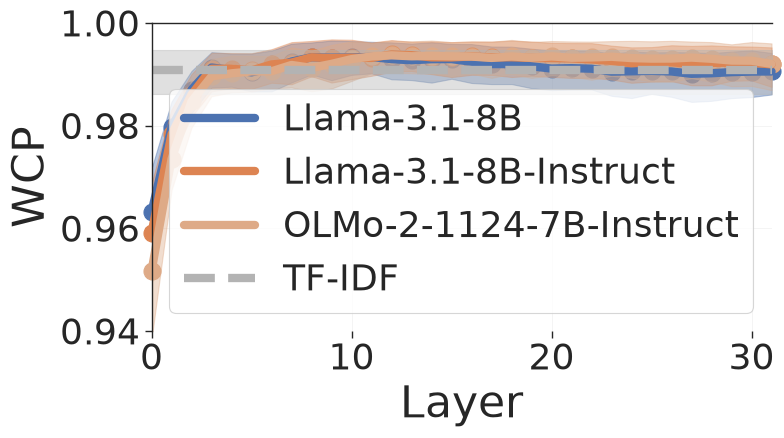

In [7]:
fig, ax = make_layers_plot(
    plot_dict=wcp_models,
    static_baselines_dict=wcp_tfidf,
    plot_main_key="WCP_mean",
    plot_ci_key="WCP_btstrp",
    ylim=(0.94,1),
    ylabel="WCP",
    models_colors={
        "OLMo-2-1124-7B-Instruct":(222/255, 170/255, 135/255),
        "TF-IDF": (179/255, 179/255, 179/255),
    },
    figsize=(8,4),
    fontsize=32,
    lw=6,
    ms=15,
)

ax.spines["bottom"].set_visible(False)
ax.spines["right"].set_visible(False)

# plt.savefig(
#     os.path.join(
#         "outputs/figures/poster_figures/", 
#         f"wcp_btstrp_zoomed_poster_small.pdf"
#     ),
#     bbox_inches='tight',
#     # transparent=True,
#     # dpi=300,
# )
plt.show()

## Cross Condition Generalisation Perfromance (CCGP)

In [8]:
ccgp_models, ccgp_tfidf  = prepare_classification_scores_for_plot(
    ccgp=True, # -> CCGP
    results_ccgp=results_ccgp_label,
    results_static=baselines_results_ccgp_label,
    loading_static_args=None,
)

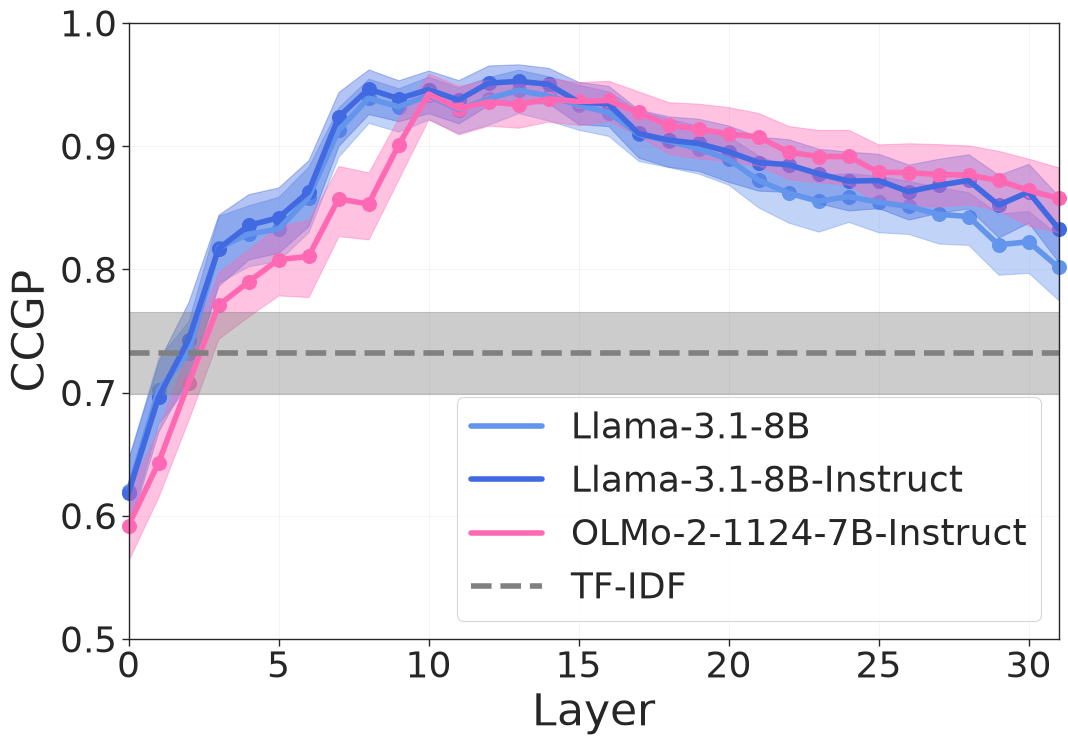

In [9]:
fig, ax = make_layers_plot(
    plot_dict=ccgp_models,
    static_baselines_dict=ccgp_tfidf,
    plot_main_key="CCGP_mean",
    plot_ci_key="CCGP_btstrp",
    ylim=(0.5,1),
    ylabel="CCGP",
    models_colors=MODELS_COLORS,
    figsize=(12,8)
)


/home/ndurandard/prep_llm_political_abstraction/scripts/visualisation/plot_classification.py:184: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


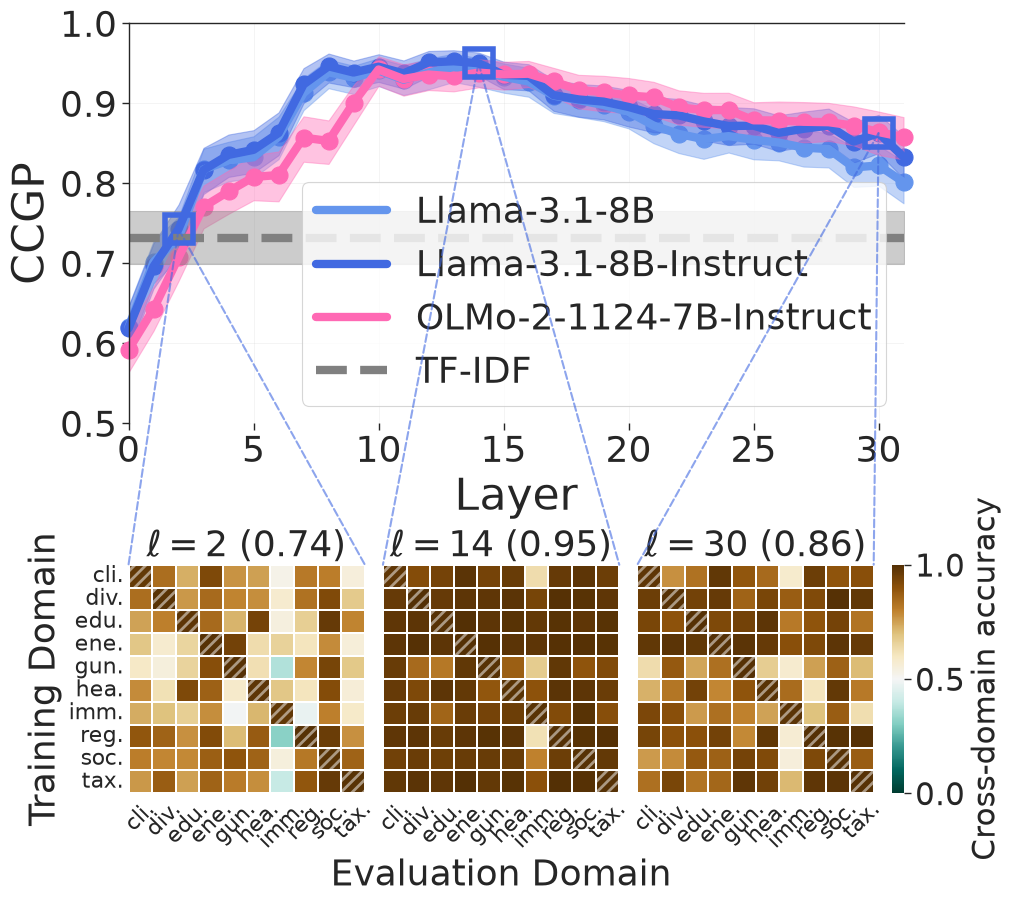

In [11]:
zoom_model='Llama-3.1-8B-Instruct'

fig, axes = make_zoomed_layers_figure(
    plot_dict=ccgp_models,
    static_baselines_dict=ccgp_tfidf,
    results_zoom_data=results_ccgp_label,  # raw data dict for building heatmaps
    zoom_model=zoom_model,
    zoom_layers=[2, 14, 30],
    models_colors=MODELS_COLORS,
    plot_main_key="CCGP_mean",
    plot_ci_key="CCGP_btstrp",
    ylabel="CCGP",
    ylim=(0.5,1),
    figsize=(10, 10),
    # cmap="PuOr_r",
    cmap="BrBG_r",

    fontsize=32,
    lw=6,
    ms=15,
)

plt.show()

## Detailed results

In [15]:
models_layers_heatmaps = {
    m: {
        l: build_heatmap(
            results_ccgp_label[m][str(l)]
        )
        for l in models_layers[m]
    }
    for m in models_names
}

findfont: Failed to find font weight semibold, now using 700.


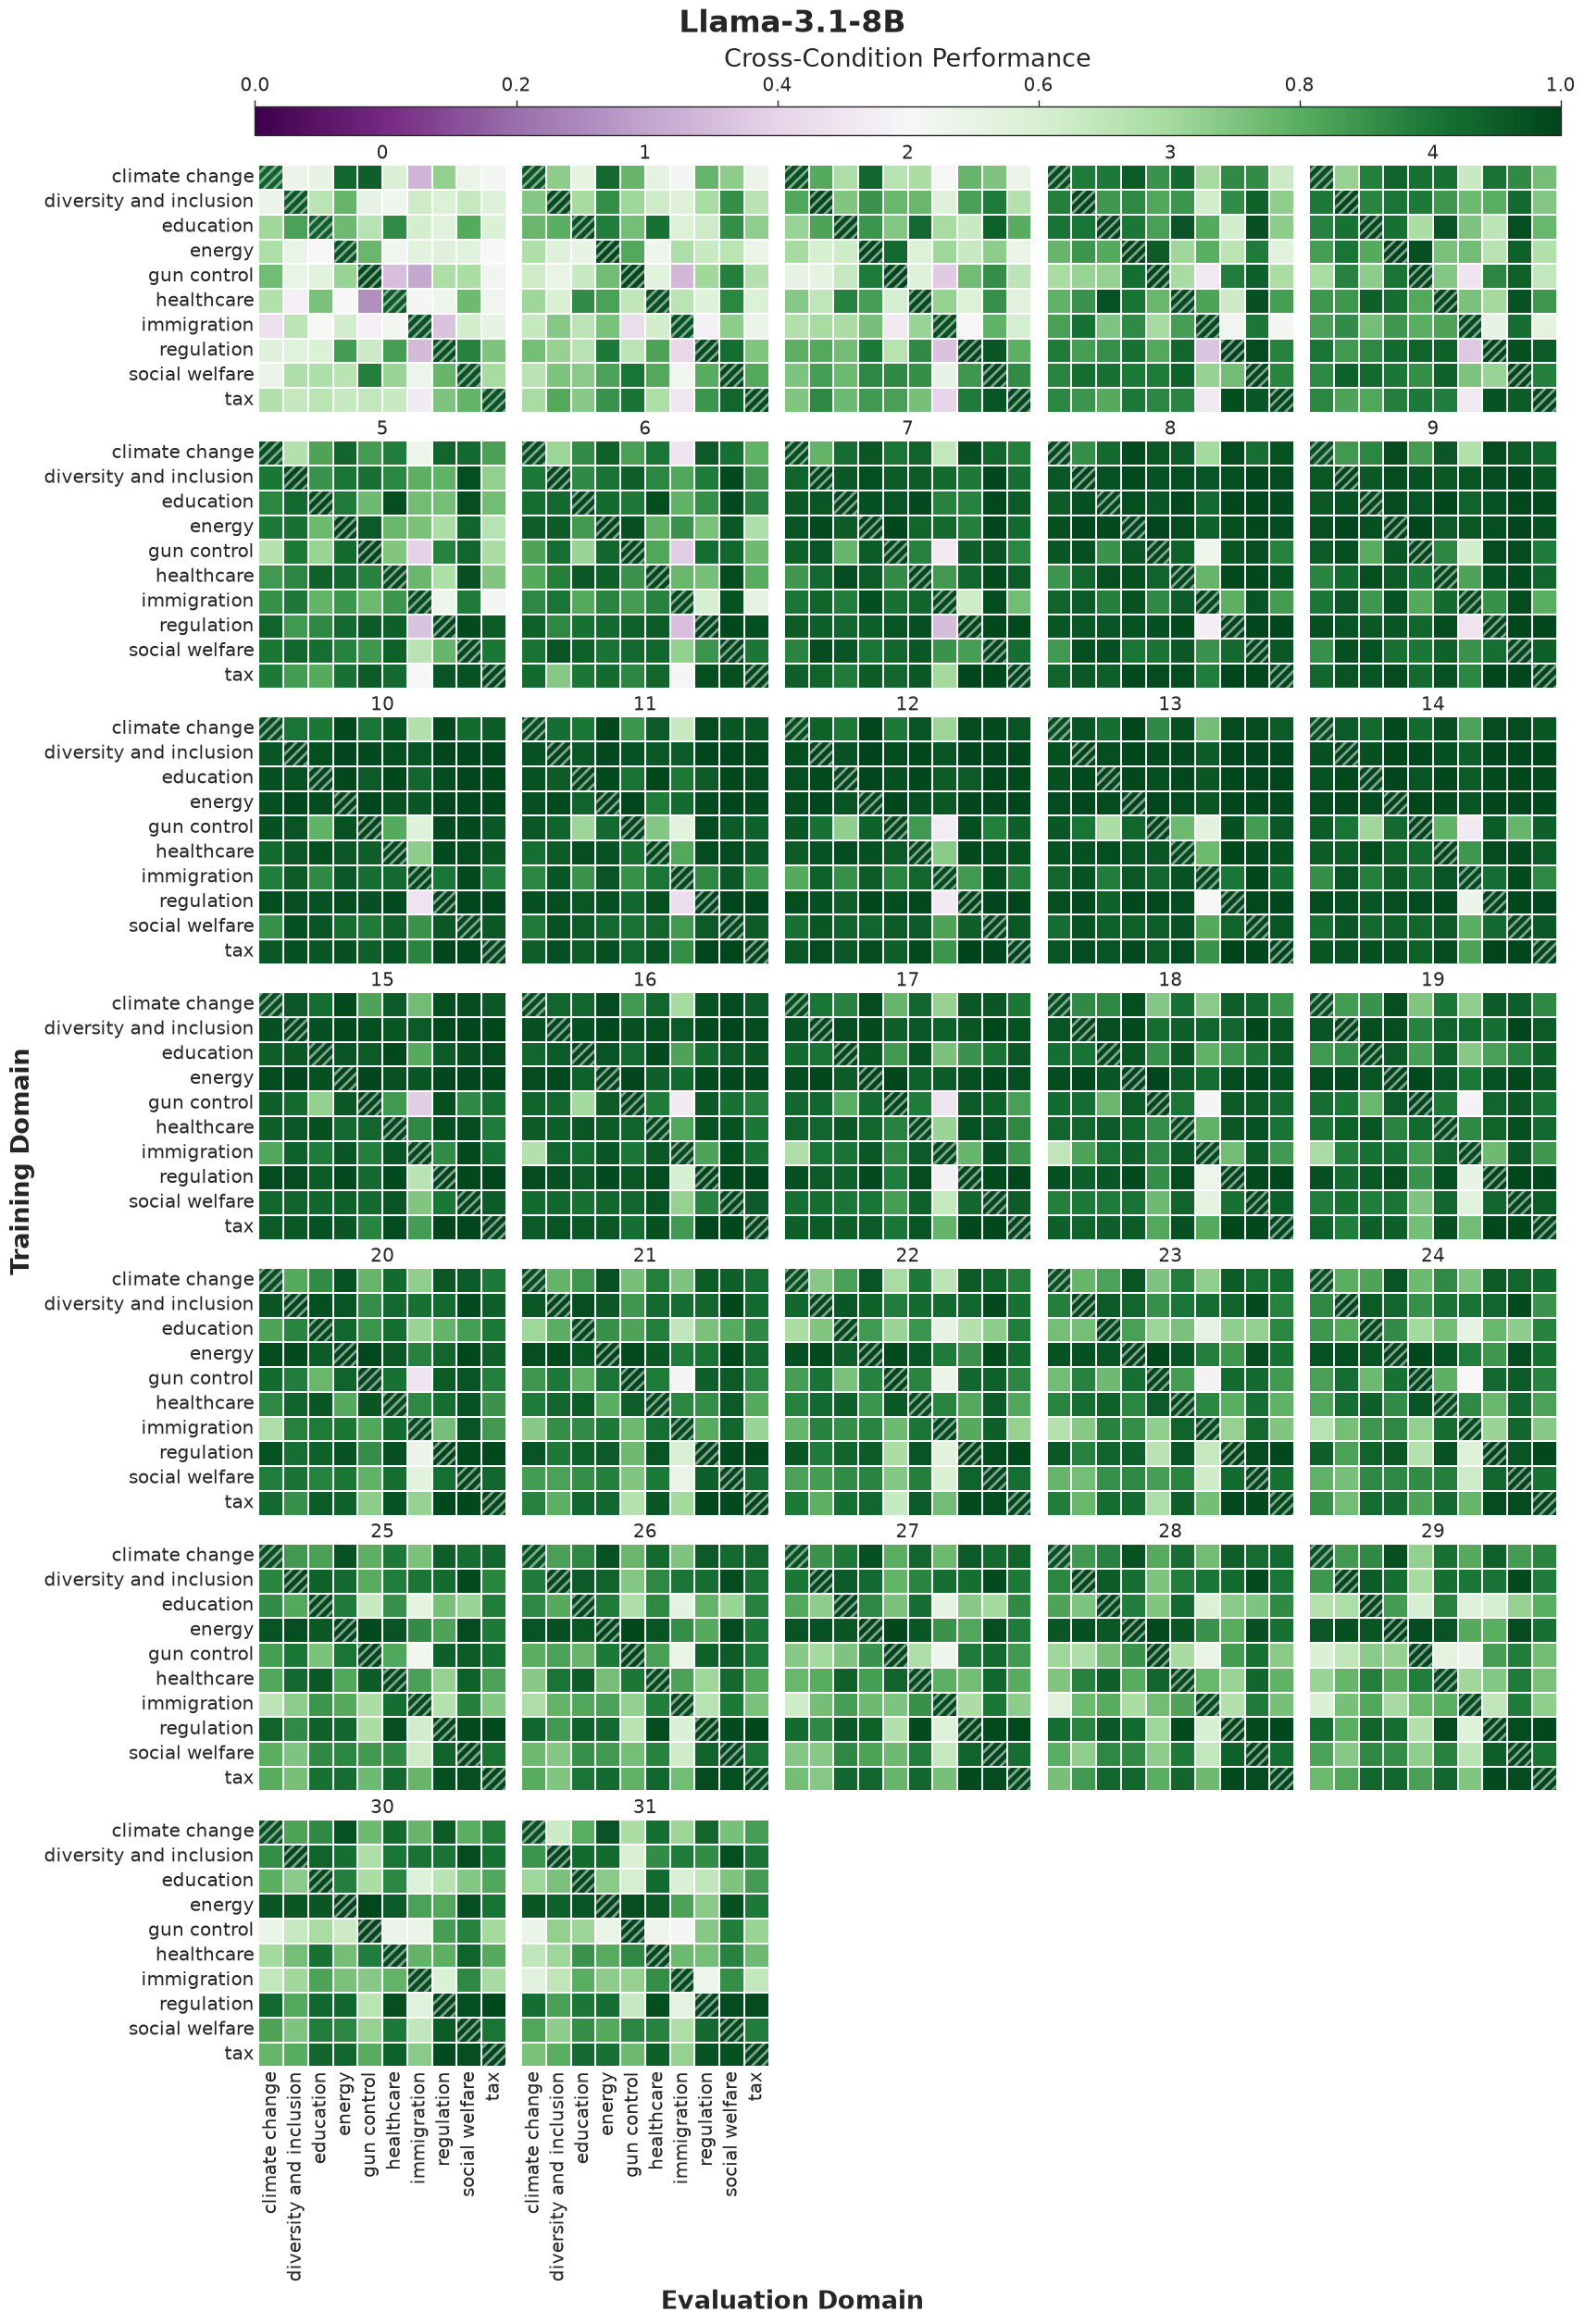

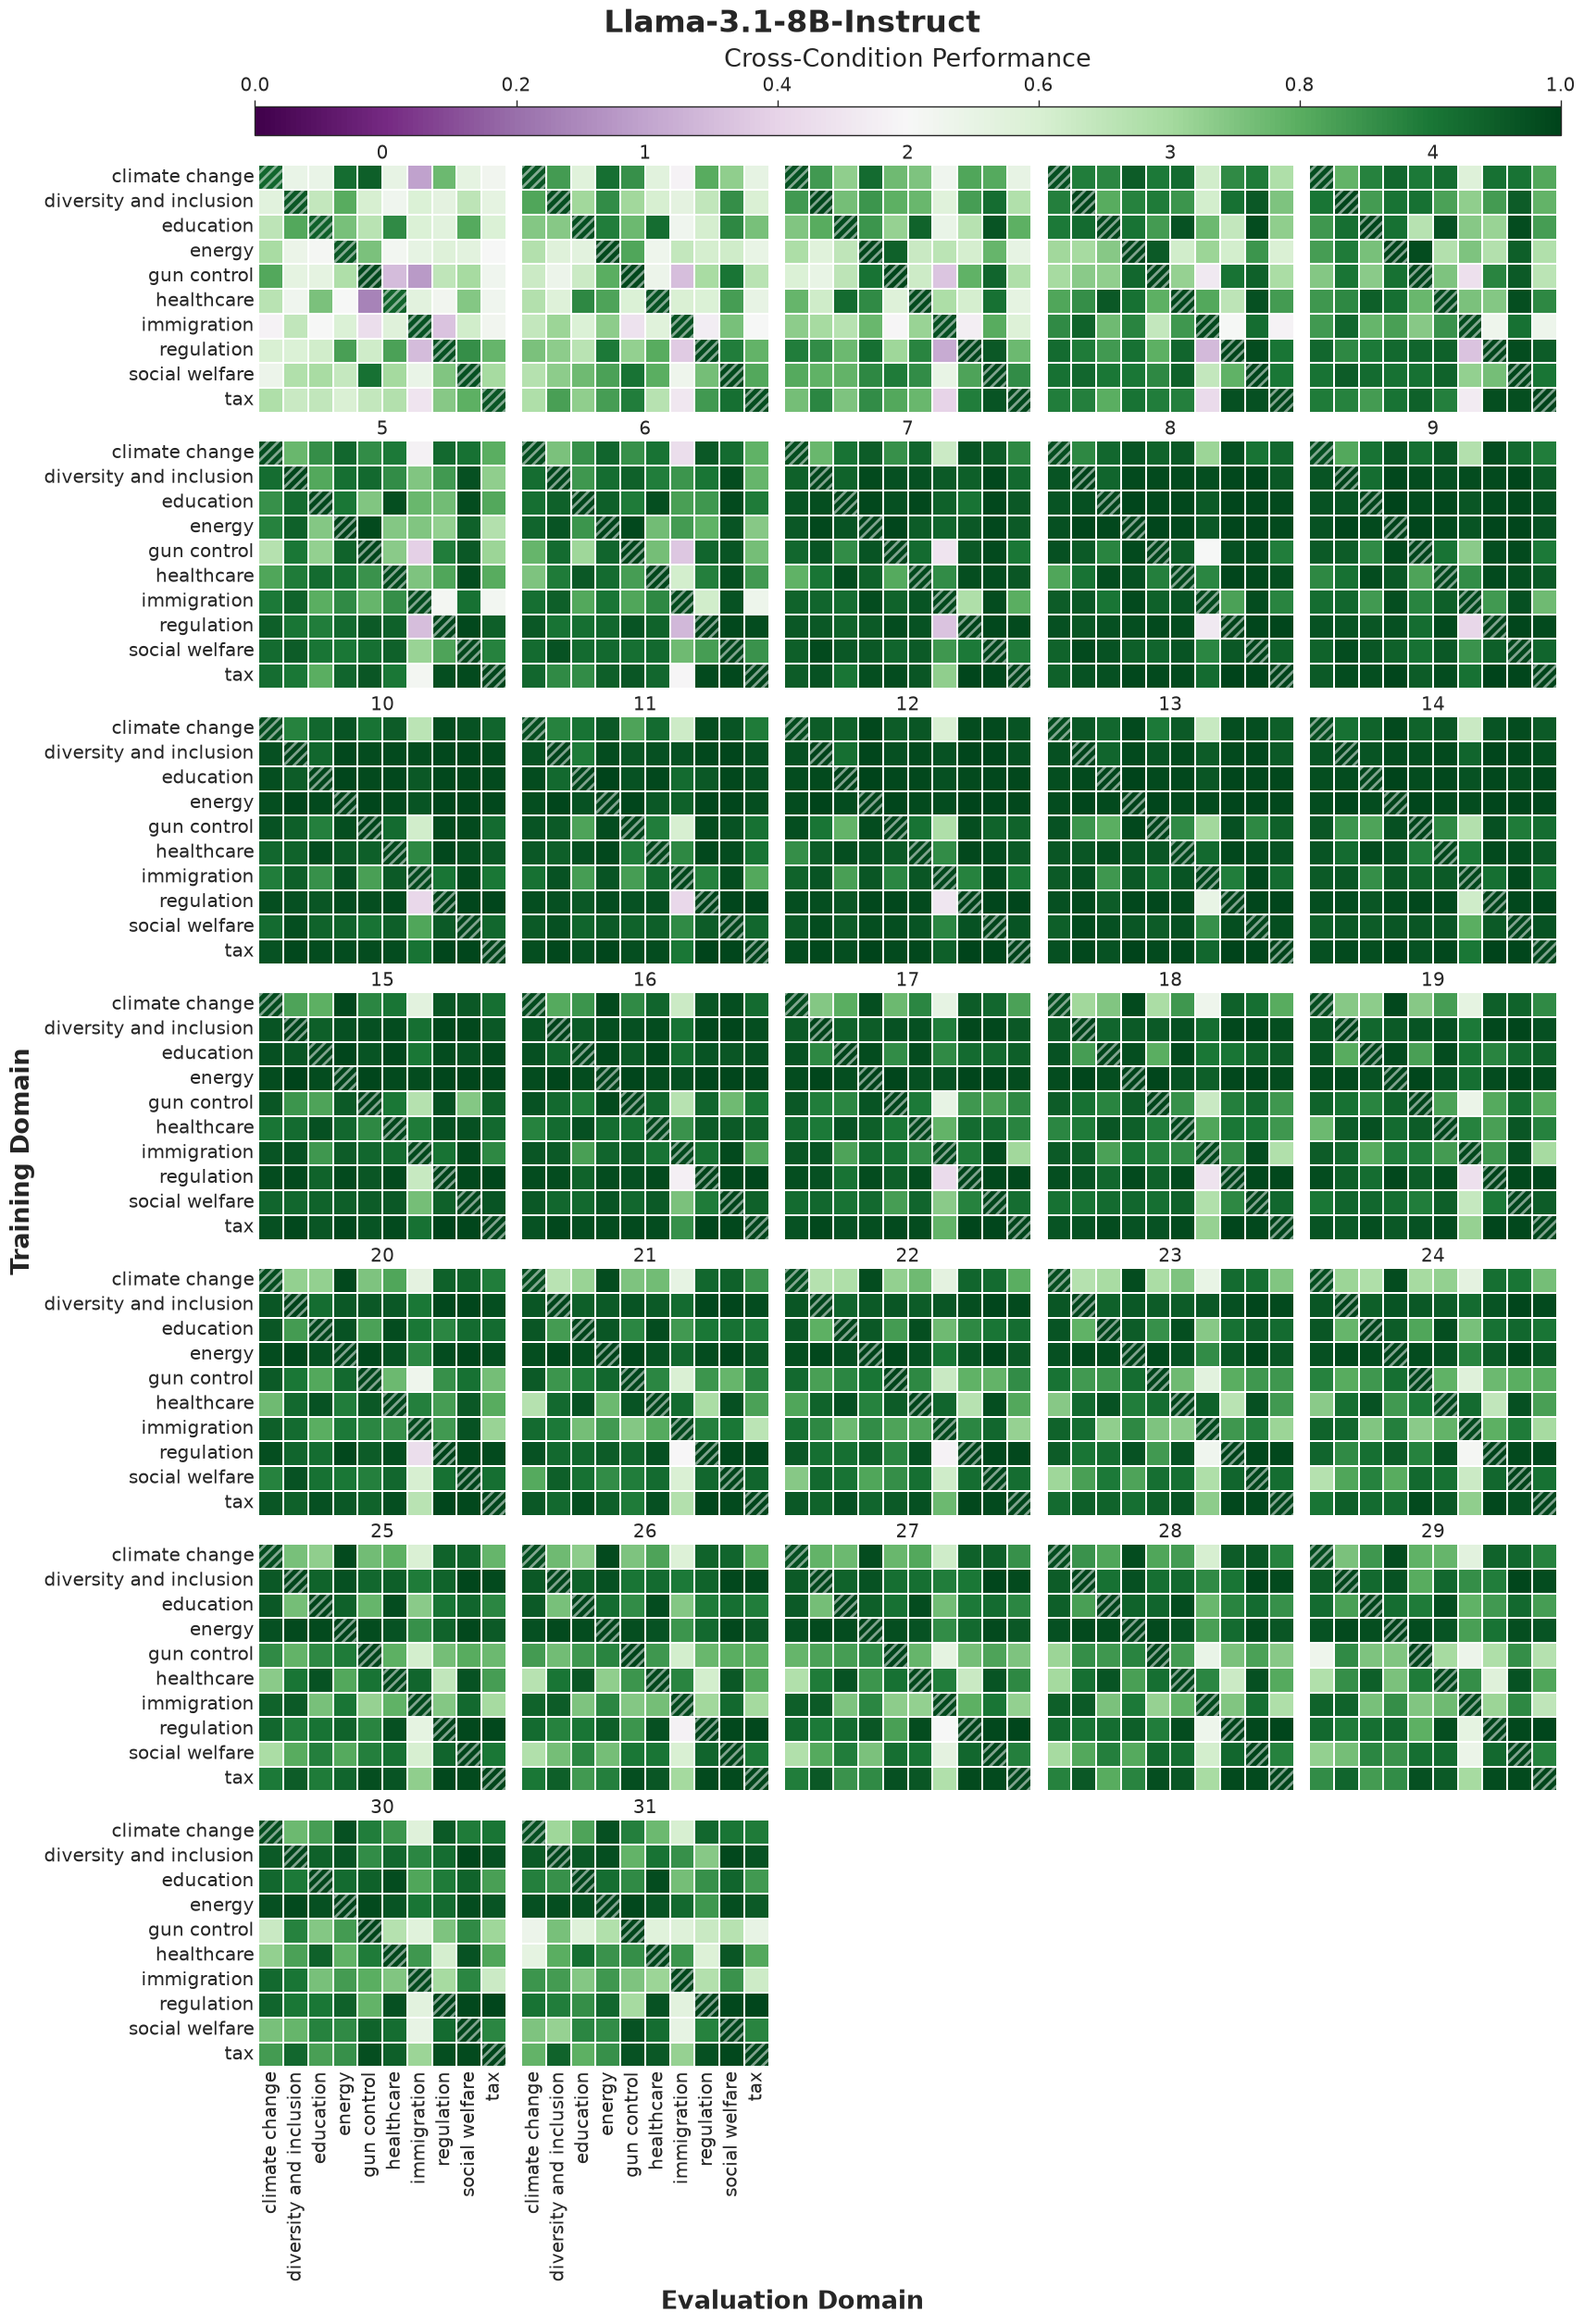

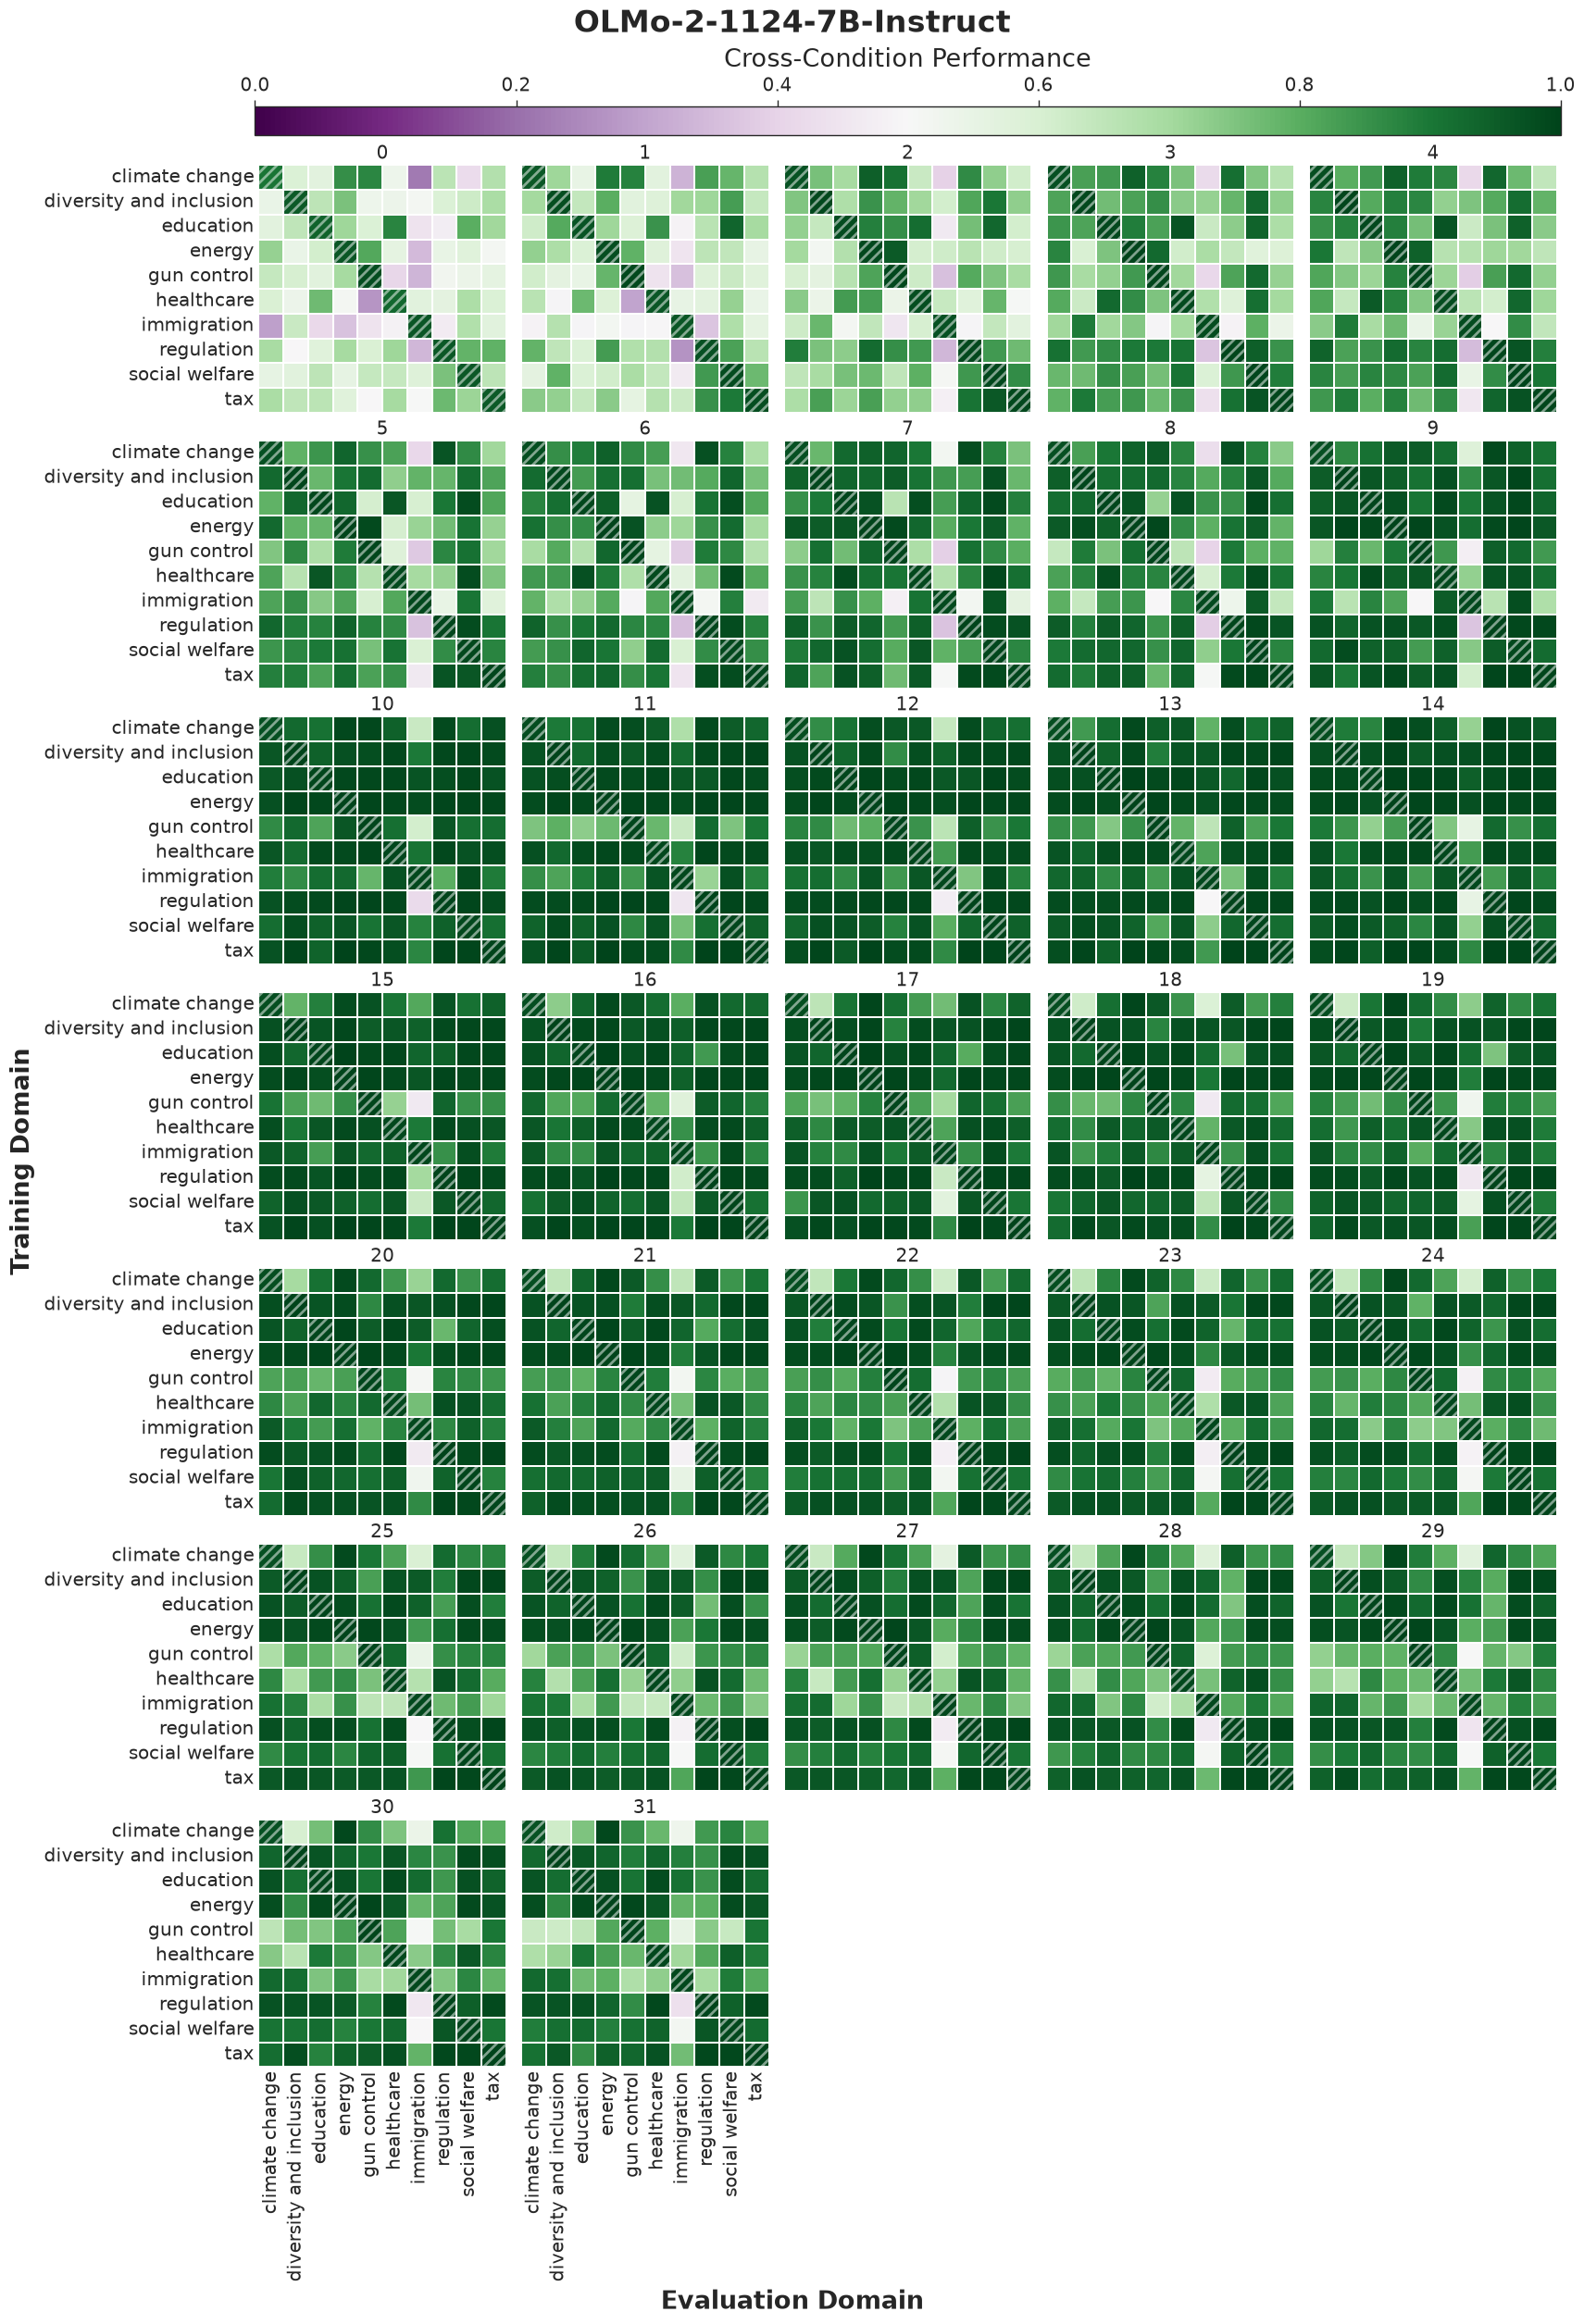

In [16]:
for m in models_names:
    make_detailed_plots(
        models_layers_heatmaps[m],
        main_title=m,
    )
    plt.show()

# Participation Ratio

In [3]:
%load_ext autoreload
%autoreload 2

from scripts.visualisation.plot_pr import *

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Load the observed, bootstraped, and null PRs

In [4]:
base_path = "./outputs/raw_outputs/pr/"
dataset_name = "twinviews"
models_names = ["Llama-3.1-8B","Llama-3.1-8B-Instruct","OLMo-2-1124-7B-Instruct"]

MODELS_COLORS = {
    "OLMo-2-1124-7B-Instruct":"hotpink",
    "Llama-3.1-8B":"cornflowerblue",
    "Llama-3.1-8B-Instruct":"royalblue",
    "TF-IDF":"grey",
}

In [5]:
# Load
n_permutations = 200
B = 100

In [6]:
# Observed

observed_prs = {}
observed_grams = {}
for model_name in models_names:
    file_prs_obs_path = os.path.join(base_path, dataset_name, f"observed_prs_{model_name}.npy")
    file_grams_obs_path = os.path.join(base_path, dataset_name, f"observed_grams_{model_name}.npy")

    observed_prs[model_name] = load_array_npy(file_prs_obs_path)
    observed_grams[model_name] = load_array_npy(file_grams_obs_path)

    models_layers = {model_name: np.arange(len(observed_prs[model_name]))}

In [7]:
# Bootstraped

models_bootstrap_prs = {}
models_bootstrap_grams = {}
for model_name in models_names:
    file_prs_btstrp_path = os.path.join(base_path, dataset_name, f"bootstraped_{B}_prs_{model_name}.npy")
    file_grams_btstrp_path = os.path.join(base_path, dataset_name, f"bootstraped_{B}_grams_{model_name}.npy")

    models_bootstrap_prs[model_name] = load_array_npy(file_prs_btstrp_path)
    models_bootstrap_grams[model_name] = load_array_npy(file_grams_btstrp_path)

In [8]:
# Bootstraped

models_null_prs = {}
for model_name in models_names:
    file_prs_null_path = os.path.join(base_path, dataset_name, f"null_{n_permutations}_prs_{model_name}.npy")

    models_null_prs[model_name] = load_array_npy(file_prs_null_path)

## Participation Ratio Plot

In [9]:
pr_plot_dict = prepare_pr_for_plot(
    observed_prs,
    models_bootstrap_prs,
    models_null_prs,
)

/home/ndurandard/prep_llm_political_abstraction/scripts/visualisation/plot_pr.py:205: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


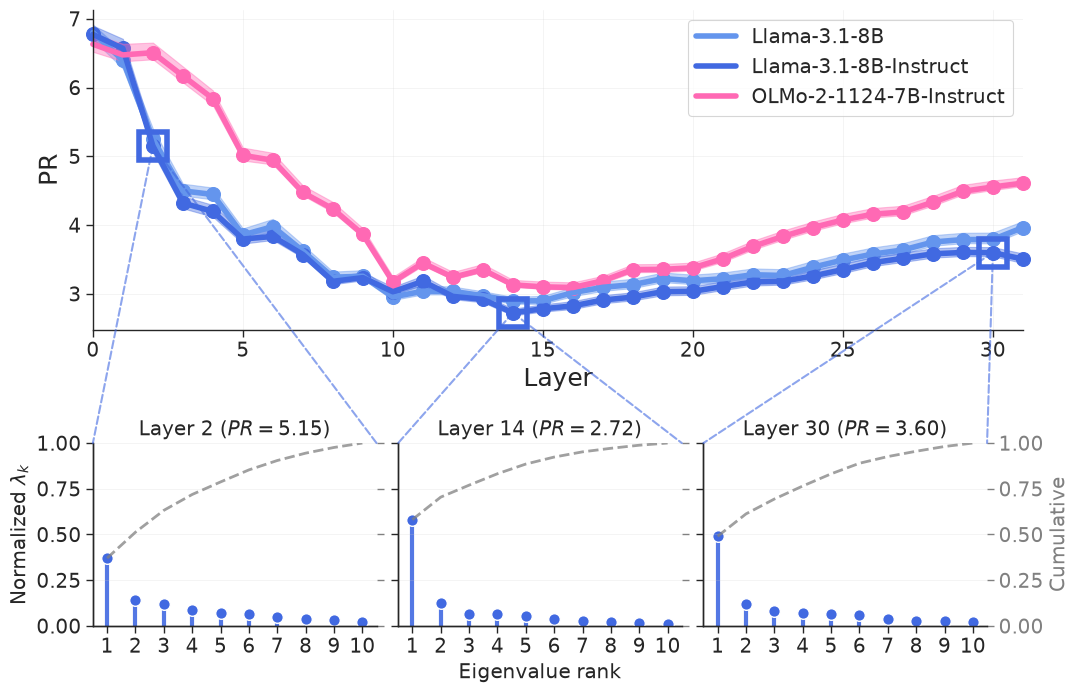

In [11]:
zoom_model="Llama-3.1-8B-Instruct"

fig, axes = make_zoomed_layers_pr_figure(
    plot_dict=pr_plot_dict,
    results_zoom_data=observed_grams,
    zoom_model=zoom_model,
    models_colors=MODELS_COLORS,
    zoom_layers=[2,14,30]
)
plt.show()

## Detailed Results

In [21]:
for m in models_names:
    models_layers_heatmaps_grams = {
        m: {
            l: observed_grams[m][l]
            for l in models_layers[m]
        }
    }

findfont: Failed to find font weight semibold, now using 700.


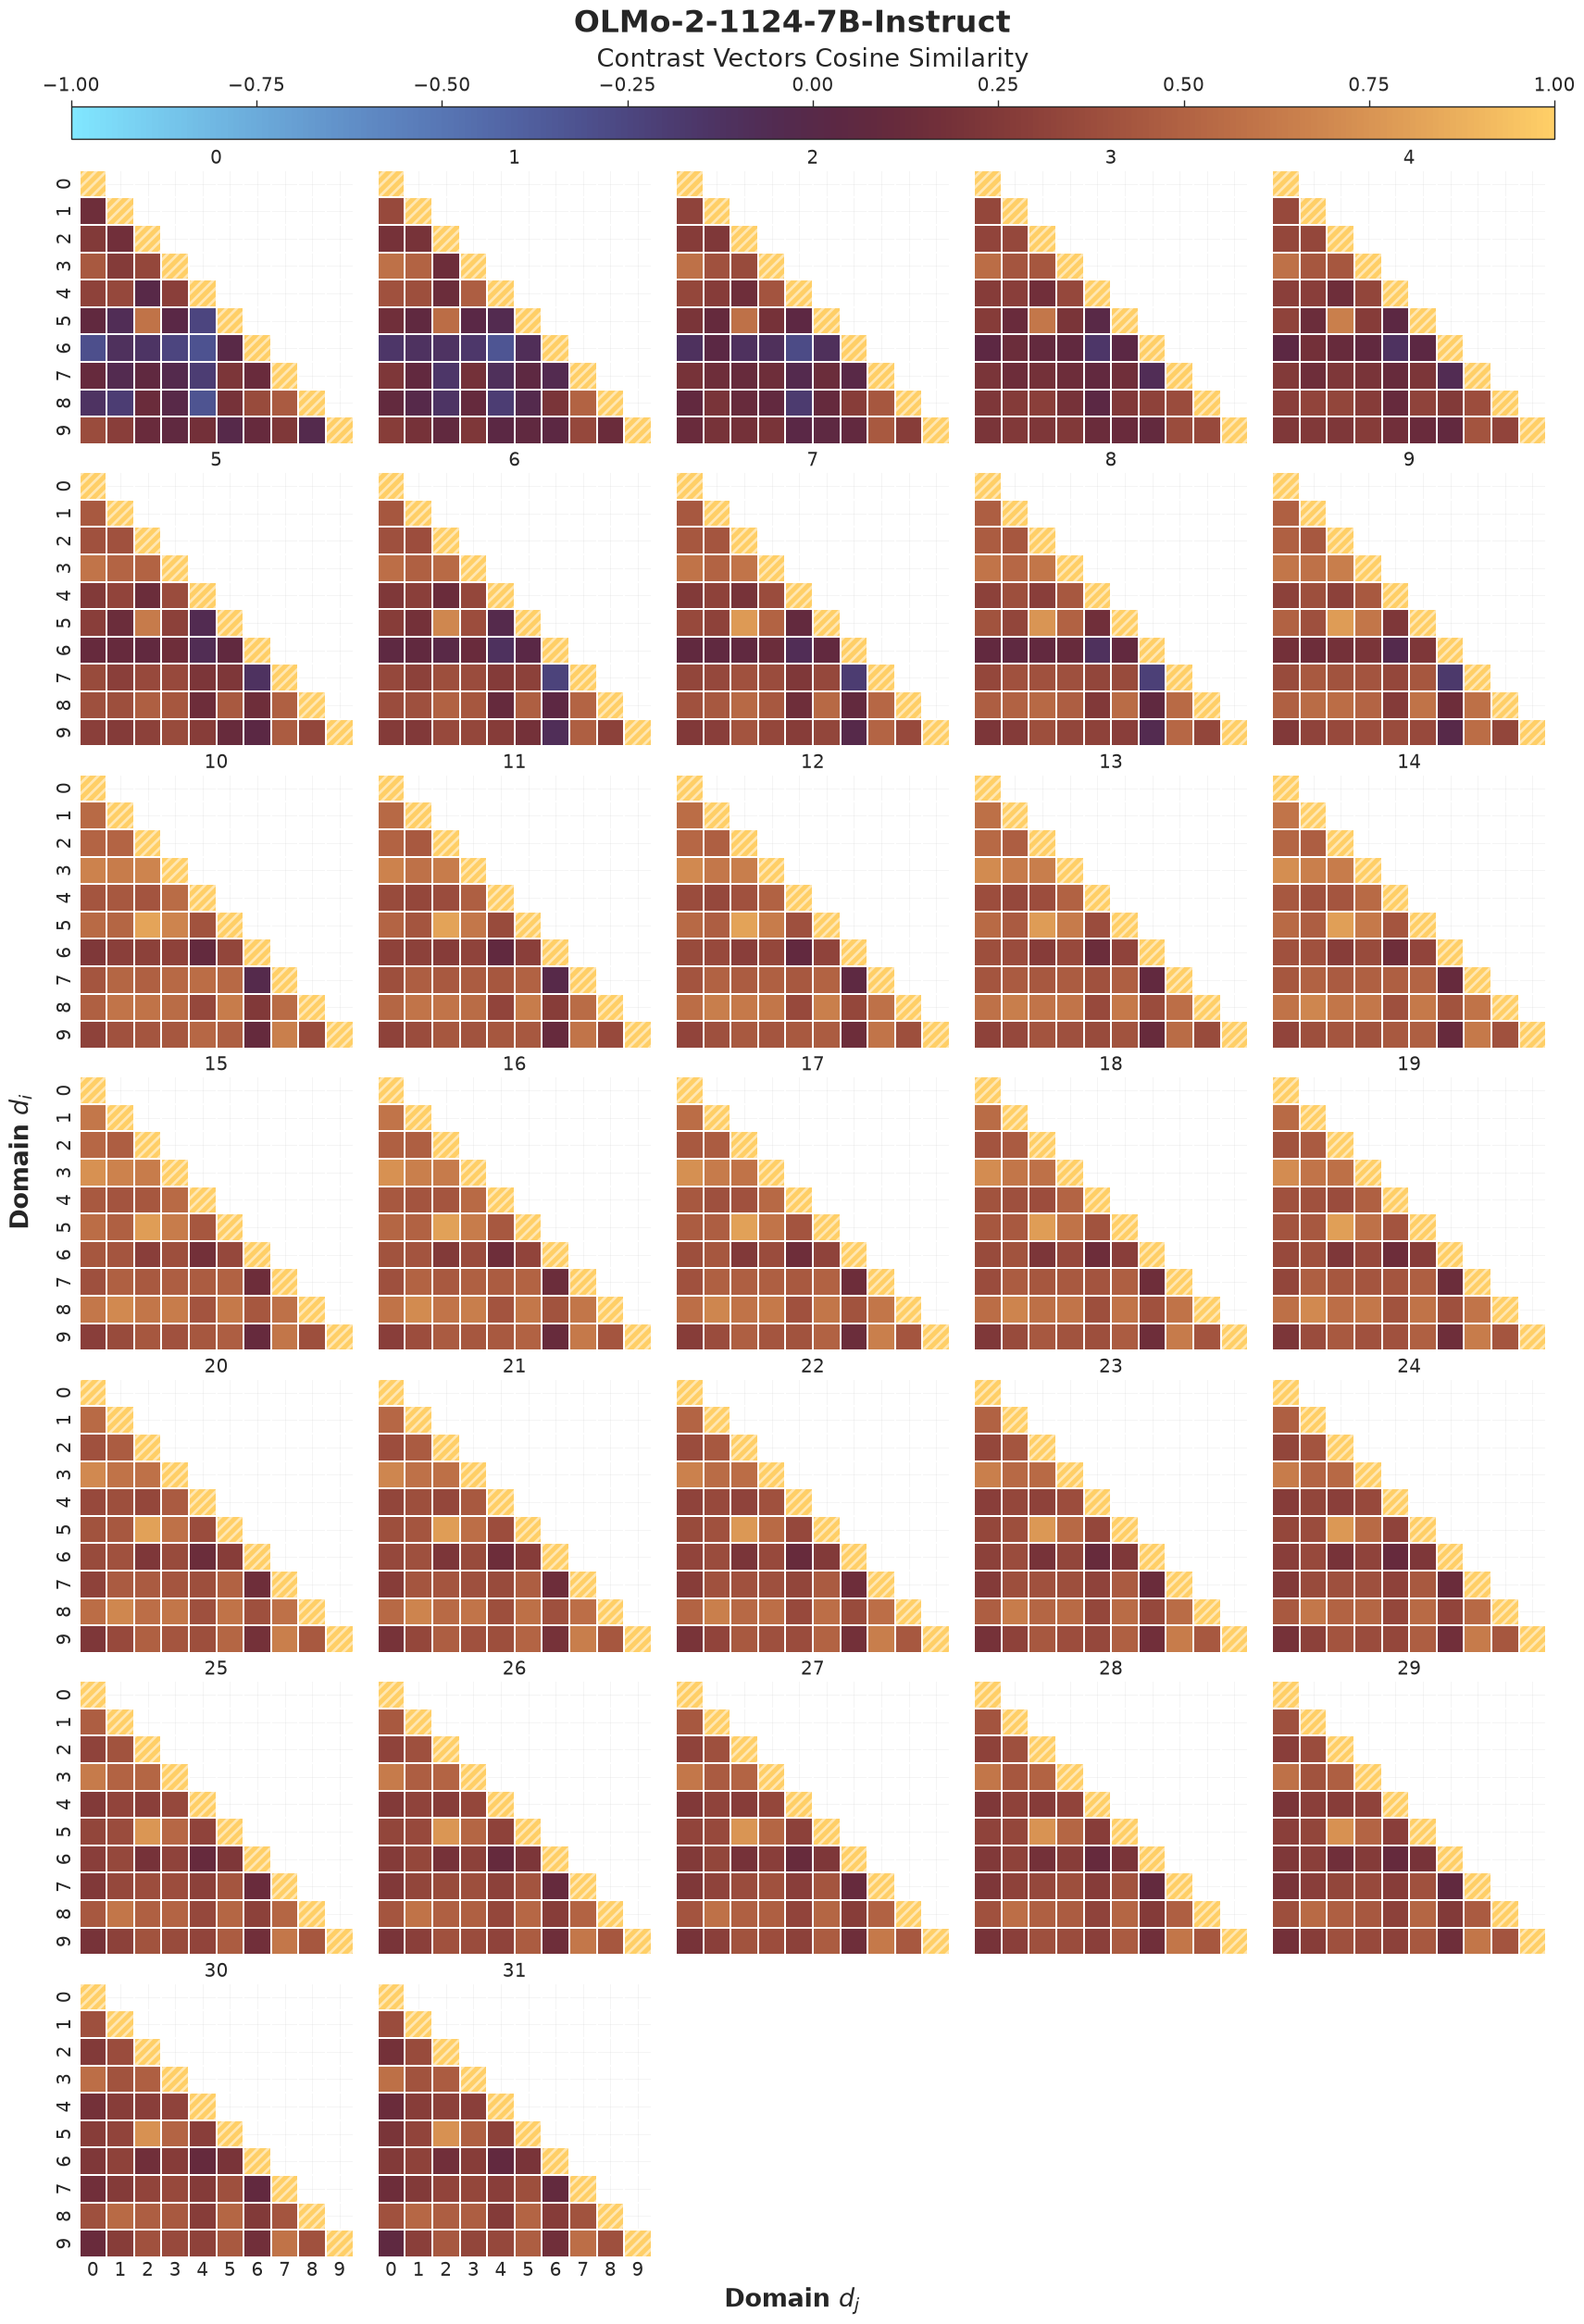

In [22]:
for m in models_names:
    make_detailed_plots(
        models_layers_heatmaps_grams[m],
        main_title=m,
        xlabel=r"Domain $d_j$",
        ylabel= r"Domain $d_i$",
        cmap="managua_r",
        vmin=-1, vmax=1,
        represented_value="Contrast Vectors Cosine Similarity",
        triangular=True
    )
    plt.show()

# CCGP-PR Correlation Plot

In [2]:
%load_ext autoreload
%autoreload 2

from scripts.visualisation import *
from scripts.visualisation.plot_classification import *
from scripts.utils import *

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
base_path_ccgp = "./outputs/raw_outputs/ccgp/"
base_path_pr = "./outputs/raw_outputs/pr/"
dataset_name = "twinviews"
models_names = ["Llama-3.1-8B","Llama-3.1-8B-Instruct","OLMo-2-1124-7B-Instruct"]

MODELS_COLORS = {
    "OLMo-2-1124-7B-Instruct":"hotpink",
    "Llama-3.1-8B":"cornflowerblue",
    "Llama-3.1-8B-Instruct":"royalblue",
    "TF-IDF":"grey",
}

In [4]:
# CCGP

results_ccgp_label = {}

for model_name in models_names:
    file_ccgp_path = os.path.join(base_path_ccgp, dataset_name, f"{model_name}.json")
    results_ccgp_label[model_name] = load_json_dict(file_ccgp_path)

ccgp_models  = prepare_classification_scores_for_plot(
    ccgp=True,
    results_ccgp=results_ccgp_label,
)

In [5]:
# PR

results_pr = {}

for model_name in models_names:
    file_prs_obs_path = os.path.join(base_path_pr, dataset_name, f"observed_prs_{model_name}.npy")
    results_pr[model_name] = load_array_npy(file_prs_obs_path)

In [6]:
plot_dict = {
    m: {
        "CCGP": ccgp_models[m]['CCGP_mean'],
        "PR": results_pr[m]
    }
    for m in models_names
}

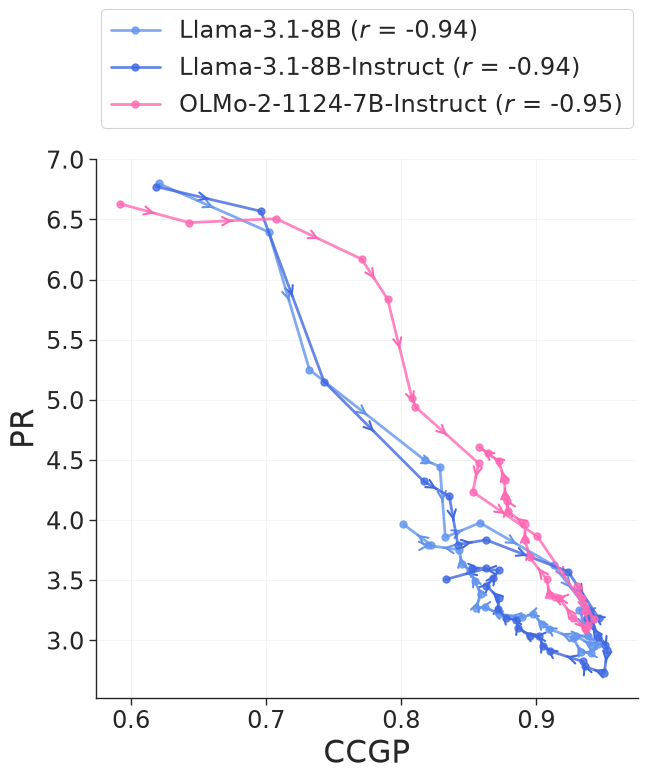

In [7]:
models_colors = {
    "OLMo-2-1124-7B-Instruct": (222/255, 135/255, 135/255),
    "TF-IDF": (179/255, 179/255, 179/255),
}

make_correlation_plot(
    plot_dict=plot_dict, # {model_name: {x_value: [], y_value: []}, ...}
    models_colors=MODELS_COLORS
)
plt.show()